# MODIS foliage data: first exploratory analysis

This notebook is the first pass over the AppEEARS download for the Maine foliage project. It does **not** compute the final brownness score. It inventories the files, checks that the raster grids agree, previews one date, and produces unfiltered provisional EVI2 time series for the three demonstration locations.

**Raw data are never modified.** All notebook outputs go to `outputs/eda/`.

## Before running

1. Put this notebook somewhere in, or next to, the project repository.
2. Set `DATA_DIR` below to the folder containing `bundle.json` and the downloaded `.tif` files. Nested subfolders are fine.
3. Run cells from top to bottom. The notebook uses only an initial *range* filter for reflectance; the formal MODIS QA mask comes later.

In [2]:
# Run this once only if your Jupyter environment lacks these packages.
# %pip install rasterio numpy pandas matplotlib pyproj

In [3]:
from pathlib import Path

# CHANGE THIS to your downloaded AppEEARS folder.
DATA_DIR = Path("/Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/data/raw/modis/appeears-ec402b03-a4fa-4412-b057-a6b05ccc027c")

# Notebook outputs are safe to delete and regenerate.
OUT_DIR = Path("outputs/eda")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# A representative autumn composite. Change this after the inventory cell if needed.
SAMPLE_DATE = "20241015"

# These are provisional anchors. Later we will use the nearest qualifying forest cell.
SITES = {
    "fort_kent": {"name": "Fort Kent", "lat": 47.2586, "lon": -68.5896},
    "rangeley": {"name": "Rangeley", "lat": 44.9687, "lon": -70.6460},
    "acadia_bar_harbor": {"name": "Acadia / Bar Harbor", "lat": 44.3876, "lon": -68.2039},
}

assert DATA_DIR.exists(), f"DATA_DIR does not exist: {DATA_DIR}"
assert (DATA_DIR / "bundle.json").exists(), "bundle.json was not found in DATA_DIR"
print(f"Reading raw data from: {DATA_DIR.resolve()}")
print(f"Writing EDA outputs to: {OUT_DIR.resolve()}")

Reading raw data from: /Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/data/raw/modis/appeears-ec402b03-a4fa-4412-b057-a6b05ccc027c
Writing EDA outputs to: /Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/notebooks/outputs/eda


In [6]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from pyproj import Transformer
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 100)

# AppEEARS file names are parsed from the final path component, so the
# notebook works whether the TIFFs are in one flat directory or nested.
FILENAME_RE = re.compile(
    r"^MOD09A1\.061_(?P<layer>.+)_(?P<date>\d{8})T\d{6}_aid\d+\.tif$"
)

REQUIRED_LAYERS = {
    "sur_refl_b01",
    "sur_refl_b02",
    "sur_refl_day_of_year",
    "sur_refl_qc_500m",
    "sur_refl_state_500m",
}

RAW_REFLECTANCE_MIN = -100
RAW_REFLECTANCE_MAX = 16000
REFLECTANCE_SCALE = 0.0001

## 1. Read the manifest and build a local inventory

The manifest is the source of truth for expected files. The local recursive search tells us whether every expected TIFF is actually present on disk.

In [7]:
with (DATA_DIR / "bundle.json").open() as f:
    bundle = json.load(f)

def parse_manifest_file(file_record):
    basename = Path(file_record["file_name"]).name
    match = FILENAME_RE.match(basename)
    if match is None:
        return None
    return {
        "layer": match["layer"],
        "date": match["date"],
        "expected_name": basename,
        "file_id": file_record["file_id"],
        "expected_size_bytes": file_record["file_size"],
    }

manifest_records = [parse_manifest_file(f) for f in bundle["files"]]
manifest_records = [r for r in manifest_records if r is not None]
manifest_df = pd.DataFrame(manifest_records)

# Recursive search accommodates AppEEARS subdirectories and a flat download folder.
local_by_name = {path.name: path for path in DATA_DIR.rglob("*.tif")}
inventory = manifest_df.copy()
inventory["local_path"] = inventory["expected_name"].map(local_by_name)
inventory["local_exists"] = inventory["local_path"].notna()
inventory["date_dt"] = pd.to_datetime(inventory["date"], format="%Y%m%d")
inventory = inventory.sort_values(["date_dt", "layer"]).reset_index(drop=True)

inventory.to_csv(OUT_DIR / "modis_inventory.csv", index=False)
print(f"AppEEARS task ID: {bundle['task_id']}")
print(f"Expected TIFFs in manifest: {len(inventory):,}")
print(f"TIFFs found locally:        {inventory.local_exists.sum():,}")
print(f"Inventory saved to:          {OUT_DIR / 'modis_inventory.csv'}")

AppEEARS task ID: ec402b03-a4fa-4412-b057-a6b05ccc027c
Expected TIFFs in manifest: 2,070
TIFFs found locally:        2,070
Inventory saved to:          outputs/eda/modis_inventory.csv


In [8]:
# Expected structure: five layers for every composite date.
layer_summary = (
    inventory.groupby("layer")
    .agg(
        files=("date", "size"),
        first_date=("date_dt", "min"),
        last_date=("date_dt", "max"),
        present_locally=("local_exists", "sum"),
    )
    .sort_index()
)
display(layer_summary)

assert set(layer_summary.index) == REQUIRED_LAYERS, (
    "Unexpected layer set. Inspect the manifest before continuing."
)

files_per_date = inventory.groupby("date")["layer"].nunique().sort_index()
incomplete_dates = files_per_date[files_per_date != len(REQUIRED_LAYERS)]
all_dates = pd.to_datetime(files_per_date.index, format="%Y%m%d")
date_gaps = pd.DataFrame({"date": all_dates})
date_gaps["days_since_previous"] = date_gaps["date"].diff().dt.days
date_gaps = date_gaps.loc[date_gaps["days_since_previous"] > 9]

print(f"Unique composite dates: {len(all_dates)}")
print(f"Incomplete date/layer groups: {len(incomplete_dates)}")
display(date_gaps)

missing_local = inventory.loc[~inventory.local_exists, ["date", "layer", "expected_name"]]
if len(missing_local):
    print("WARNING: files listed in the manifest but not found locally:")
    display(missing_local.head(20))
else:
    print("All manifest TIFFs were found locally.")

,files,first_date,last_date,present_locally
layer,,,,
sur_refl_b01,414,2016-12-26,2025-12-27,414
sur_refl_b02,414,2016-12-26,2025-12-27,414
sur_refl_day_of_year,414,2016-12-26,2025-12-27,414
sur_refl_qc_500m,414,2016-12-26,2025-12-27,414
sur_refl_state_500m,414,2016-12-26,2025-12-27,414


Unique composite dates: 414
Incomplete date/layer groups: 0


,date,days_since_previous
267,2022-10-24,16.0


All manifest TIFFs were found locally.


The expected result for this task is 2,070 TIFFs: 414 dates times five layers. A gap in the date sequence is not necessarily a download error; keep it documented and let later temporal smoothing span it rather than inventing an observation.

In [9]:
# Preserve supporting files. The QC lookup is useful when we build the formal QA mask.
supporting_files = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".csv", ".json", ".xml", ".md", ".txt"}
)
for path in supporting_files:
    print(path.relative_to(DATA_DIR))

lookup_files = list(DATA_DIR.rglob("*lookup*.csv"))
if lookup_files:
    print("\nPreview of the MODIS QA lookup table:")
    display(pd.read_csv(lookup_files[0]).head())

bundle.json


## 2. Inspect one matched red/NIR/QA/date set

Choose `SAMPLE_DATE` above from the inventory. This confirms CRS, raster shape, raw value range, nodata behavior, and alignment before any reprojection or aggregation.

In [10]:
def path_for(layer, date=SAMPLE_DATE):
    rows = inventory.loc[(inventory["layer"] == layer) & (inventory["date"] == date)]
    if len(rows) != 1:
        raise ValueError(f"Expected one file for {layer=} and {date=}; found {len(rows)}")
    path = rows.iloc[0]["local_path"]
    if pd.isna(path) or not Path(path).exists():
        raise FileNotFoundError(f"Local TIFF missing for {layer=} and {date=}.")
    return Path(path)

sample_paths = {layer: path_for(layer) for layer in sorted(REQUIRED_LAYERS)}
sample_paths

{'sur_refl_b01': PosixPath('/Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/data/raw/modis/appeears-ec402b03-a4fa-4412-b057-a6b05ccc027c/MOD09A1.061_sur_refl_b01_20241015T000000_aid0001.tif'),
 'sur_refl_b02': PosixPath('/Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/data/raw/modis/appeears-ec402b03-a4fa-4412-b057-a6b05ccc027c/MOD09A1.061_sur_refl_b02_20241015T000000_aid0001.tif'),
 'sur_refl_day_of_year': PosixPath('/Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/data/raw/modis/appeears-ec402b03-a4fa-4412-b057-a6b05ccc027c/MOD09A1.061_sur_refl_day_of_year_20241015T000000_aid0001.tif'),
 'sur_refl_qc_500m': PosixPath('/Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/data/raw/modis/appeears-ec402b03-a4fa-4412-b057-a6b05ccc027c/MOD09A1.061_sur_refl_qc_500m_20241015T000000_aid0001.tif'),
 'sur_refl_state_500m': PosixPath('/Users/ethanfazal/Documents/Fall-26/im2c-fall-foliage/data/raw/modis/appeears-ec402b03-a4fa-4412-b057-a6b05ccc027c/MOD09A1.061_sur_refl_state_500

In [11]:
def raster_metadata(path):
    with rasterio.open(path) as src:
        return {
            "file": path.name,
            "crs": str(src.crs),
            "width": src.width,
            "height": src.height,
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "transform": str(src.transform),
            "bounds": tuple(round(v, 2) for v in src.bounds),
            "res": src.res,
        }

metadata_df = pd.DataFrame([raster_metadata(path) for path in sample_paths.values()])
display(metadata_df)
metadata_df.to_json(OUT_DIR / f"sample_metadata_{SAMPLE_DATE}.json", orient="records", indent=2)

# Red, NIR, and QA grids must line up exactly.
with rasterio.open(sample_paths["sur_refl_b01"]) as reference:
    reference_signature = (reference.crs, reference.transform, reference.width, reference.height)

for layer, path in sample_paths.items():
    with rasterio.open(path) as src:
        signature = (src.crs, src.transform, src.width, src.height)
    assert signature == reference_signature, f"Grid mismatch in {layer}"

print("All five sample rasters have identical CRS, transform, and shape.")

,file,crs,width,height,dtype,nodata,transform,bounds,res
0,MOD09A1.061_sur_refl_b01_20241015T000000_aid00...,"PROJCS[""unknown"",GEOGCS[""unknown"",DATUM[""unkno...",1383,1114,int16,-2.867200e+04,"| 463.31, 0.00,-5757123.82|\n| 0.00,-463.31, 5...","(-5757123.82, 4771657.67, -5116362.33, 5287788...","(463.312716525, 463.312716525)"
1,MOD09A1.061_sur_refl_b02_20241015T000000_aid00...,"PROJCS[""unknown"",GEOGCS[""unknown"",DATUM[""unkno...",1383,1114,int16,-2.867200e+04,"| 463.31, 0.00,-5757123.82|\n| 0.00,-463.31, 5...","(-5757123.82, 4771657.67, -5116362.33, 5287788...","(463.312716525, 463.312716525)"
2,MOD09A1.061_sur_refl_day_of_year_20241015T0000...,"PROJCS[""unknown"",GEOGCS[""unknown"",DATUM[""unkno...",1383,1114,uint16,6.553500e+04,"| 463.31, 0.00,-5757123.82|\n| 0.00,-463.31, 5...","(-5757123.82, 4771657.67, -5116362.33, 5287788...","(463.312716525, 463.312716525)"
3,MOD09A1.061_sur_refl_qc_500m_20241015T000000_a...,"PROJCS[""unknown"",GEOGCS[""unknown"",DATUM[""unkno...",1383,1114,uint32,4.294967e+09,"| 463.31, 0.00,-5757123.82|\n| 0.00,-463.31, 5...","(-5757123.82, 4771657.67, -5116362.33, 5287788...","(463.312716525, 463.312716525)"
4,MOD09A1.061_sur_refl_state_500m_20241015T00000...,"PROJCS[""unknown"",GEOGCS[""unknown"",DATUM[""unkno...",1383,1114,uint16,6.553500e+04,"| 463.31, 0.00,-5757123.82|\n| 0.00,-463.31, 5...","(-5757123.82, 4771657.67, -5116362.33, 5287788...","(463.312716525, 463.312716525)"


All five sample rasters have identical CRS, transform, and shape.


In [12]:
def read_band(path):
    with rasterio.open(path) as src:
        return src.read(1), src.profile

red_raw, profile = read_band(sample_paths["sur_refl_b01"])
nir_raw, _ = read_band(sample_paths["sur_refl_b02"])
qc_raw, _ = read_band(sample_paths["sur_refl_qc_500m"])
state_raw, _ = read_band(sample_paths["sur_refl_state_500m"])
doy_raw, _ = read_band(sample_paths["sur_refl_day_of_year"])

def numeric_summary(array, name):
    finite = array[np.isfinite(array)]
    return {
        "layer": name,
        "dtype": str(array.dtype),
        "min": float(np.min(finite)),
        "p01": float(np.percentile(finite, 1)),
        "median": float(np.median(finite)),
        "p99": float(np.percentile(finite, 99)),
        "max": float(np.max(finite)),
        "unique_values": int(np.unique(array).size),
    }

display(pd.DataFrame([
    numeric_summary(red_raw, "red_raw"),
    numeric_summary(nir_raw, "nir_raw"),
    numeric_summary(qc_raw, "qc_raw"),
    numeric_summary(state_raw, "state_raw"),
    numeric_summary(doy_raw, "day_of_year"),
]))

print("Most frequent raw QC values:")
display(pd.Series(qc_raw.ravel(), name="count").value_counts().head(15).to_frame())
print("Most frequent raw state-QA values:")
display(pd.Series(state_raw.ravel(), name="count").value_counts().head(15).to_frame())

,layer,dtype,min,p01,median,p99,max,unique_values
0,red_raw,int16,-2.867200e+04,-2.867200e+04,-2.867200e+04,7.640000e+02,4.620000e+03,1334
1,nir_raw,int16,-2.867200e+04,-2.867200e+04,-2.867200e+04,2.929000e+03,5.657000e+03,3978
2,qc_raw,uint32,1.073742e+09,1.073742e+09,4.294967e+09,4.294967e+09,4.294967e+09,151
3,state_raw,uint16,8.000000e+00,6.400000e+01,6.553500e+04,6.553500e+04,6.553500e+04,56
4,day_of_year,uint16,2.890000e+02,2.920000e+02,6.553500e+04,6.553500e+04,6.553500e+04,8


Most frequent raw QC values:


,count
count,
4294967295,1031750
1073741824,390965
1075576832,48914
1075838976,24947
1073742657,5771
2016674627,5617
1077150529,5611
1077149697,3257
2013266755,3175


Most frequent raw state-QA values:


,count
count,
65535,1031750
72,228115
80,131012
136,68613
64,28382
128,27173
88,20427
65,1384
138,1118


## 3. Preliminary EVI2 map

This cell applies the documented `0.0001` reflectance scale and removes only fill/out-of-range reflectance values. It deliberately does **not** apply the final cloud, shadow, snow, water, or forest mask yet. Treat the output as a sanity check, not final analysis.

In [13]:
valid_reflectance = (
    (red_raw >= RAW_REFLECTANCE_MIN) & (red_raw <= RAW_REFLECTANCE_MAX) &
    (nir_raw >= RAW_REFLECTANCE_MIN) & (nir_raw <= RAW_REFLECTANCE_MAX)
)

red = np.where(valid_reflectance, red_raw * REFLECTANCE_SCALE, np.nan)
nir = np.where(valid_reflectance, nir_raw * REFLECTANCE_SCALE, np.nan)
denominator = nir + 2.4 * red + 1.0
evi2_preliminary = np.full(red.shape, np.nan, dtype=float)
np.divide(2.5 * (nir - red), denominator, out=evi2_preliminary, where=valid_reflectance & (denominator != 0))

print(f"Pixels surviving only the raw-range check: {valid_reflectance.mean():.1%}")
print("Preliminary EVI2 summary (before formal QA):")
display(pd.Series(evi2_preliminary[np.isfinite(evi2_preliminary)]).describe(percentiles=[.01, .05, .5, .95, .99]))

Pixels surviving only the raw-range check: 33.0%
Preliminary EVI2 summary (before formal QA):


count    508912.000000
mean          0.266374
std           0.116655
min          -0.079335
1%           -0.018926
5%           -0.005962
50%           0.296390
95%           0.398389
99%           0.438528
max           0.753824
dtype: float64

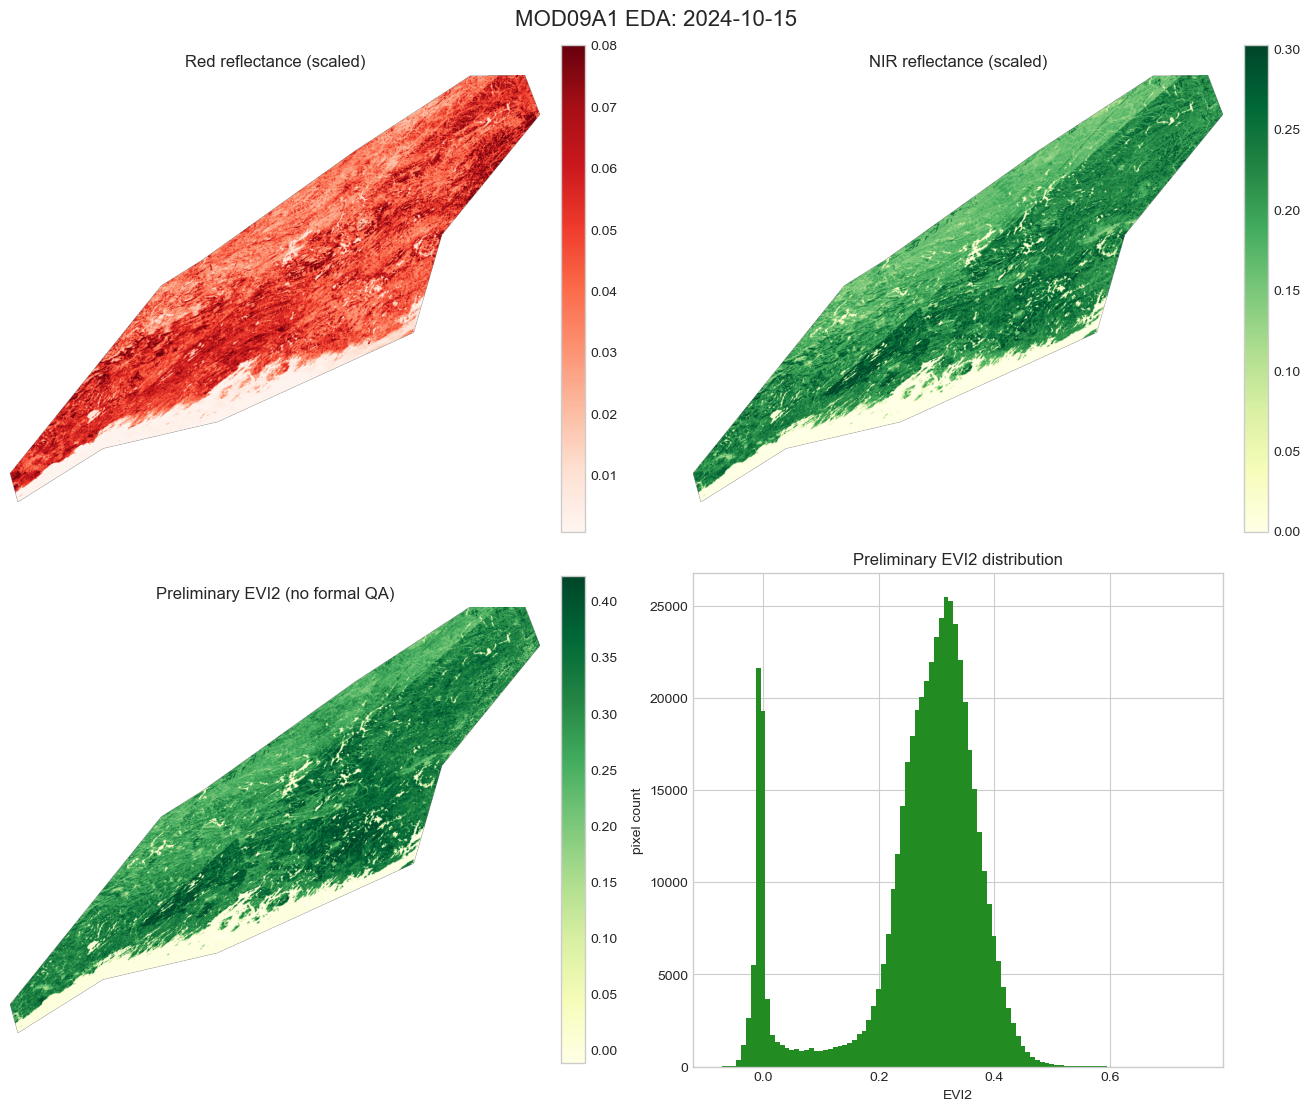

Saved: outputs/eda/snapshot_20241015.png


In [14]:
def plot_raster(ax, array, title, cmap):
    finite = array[np.isfinite(array)]
    vmin, vmax = np.percentile(finite, [2, 98])
    image = ax.imshow(array, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_axis_off()
    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
plot_raster(axes[0, 0], red, "Red reflectance (scaled)", "Reds")
plot_raster(axes[0, 1], nir, "NIR reflectance (scaled)", "YlGn")
plot_raster(axes[1, 0], evi2_preliminary, "Preliminary EVI2 (no formal QA)", "YlGn")
axes[1, 1].hist(evi2_preliminary[np.isfinite(evi2_preliminary)], bins=100, color="forestgreen")
axes[1, 1].set(title="Preliminary EVI2 distribution", xlabel="EVI2", ylabel="pixel count")
fig.suptitle(f"MOD09A1 EDA: {pd.Timestamp(SAMPLE_DATE).strftime('%Y-%m-%d')}", fontsize=16)
figure_path = OUT_DIR / f"snapshot_{SAMPLE_DATE}.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved: {figure_path}")

## 4. Provisional EVI2 time series at the three sites

This samples the native MODIS pixel containing each coordinate. It is intentionally preliminary: the final pipeline will use the nearest qualifying forest cell and a full QA mask. Even so, these plots are the quickest way to detect bad scaling, a wrong CRS, or unexpected seasonal behavior.

In [15]:
# One red and one NIR path per date. Do not continue if either is missing.
wide_paths = inventory.pivot(index="date", columns="layer", values="local_path").sort_index()
wide_paths = wide_paths.dropna(subset=["sur_refl_b01", "sur_refl_b02"])

def sample_raw_values(path, sites):
    with rasterio.open(path) as src:
        transformer = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
        xy = [transformer.transform(site["lon"], site["lat"]) for site in sites.values()]
        values = [sample[0] for sample in src.sample(xy)]
    return values

records = []
for date, paths in wide_paths.iterrows():
    red_values = sample_raw_values(Path(paths["sur_refl_b01"]), SITES)
    nir_values = sample_raw_values(Path(paths["sur_refl_b02"]), SITES)

    for (site_id, site), red_value, nir_value in zip(SITES.items(), red_values, nir_values):
        valid = (
            RAW_REFLECTANCE_MIN <= red_value <= RAW_REFLECTANCE_MAX and
            RAW_REFLECTANCE_MIN <= nir_value <= RAW_REFLECTANCE_MAX
        )
        if valid:
            red_value = red_value * REFLECTANCE_SCALE
            nir_value = nir_value * REFLECTANCE_SCALE
            denominator = nir_value + 2.4 * red_value + 1.0
            evi2 = 2.5 * (nir_value - red_value) / denominator if denominator != 0 else np.nan
        else:
            red_value, nir_value, evi2 = np.nan, np.nan, np.nan

        records.append({
            "site_id": site_id,
            "site_name": site["name"],
            "date": pd.to_datetime(date, format="%Y%m%d"),
            "red": red_value,
            "nir": nir_value,
            "evi2_preliminary": evi2,
        })

site_ts = pd.DataFrame(records)
site_ts["year"] = site_ts["date"].dt.year
site_ts["doy"] = site_ts["date"].dt.dayofyear
site_ts.to_csv(OUT_DIR / "provisional_site_evi2.csv", index=False)
display(site_ts.head())
print(f"Saved: {OUT_DIR / 'provisional_site_evi2.csv'}")

,site_id,site_name,date,red,nir,evi2_preliminary,year,doy
0,fort_kent,Fort Kent,2016-12-26,0.6699,0.7010,0.023498,2016,361
1,rangeley,Rangeley,2016-12-26,0.3052,0.3992,0.110242,2016,361
2,acadia_bar_harbor,Acadia / Bar Harbor,2016-12-26,0.0238,0.0403,0.037588,2016,361
3,fort_kent,Fort Kent,2017-01-01,0.6699,0.7010,0.023498,2017,1
4,rangeley,Rangeley,2017-01-01,0.3628,0.4071,0.048621,2017,1


Saved: outputs/eda/provisional_site_evi2.csv


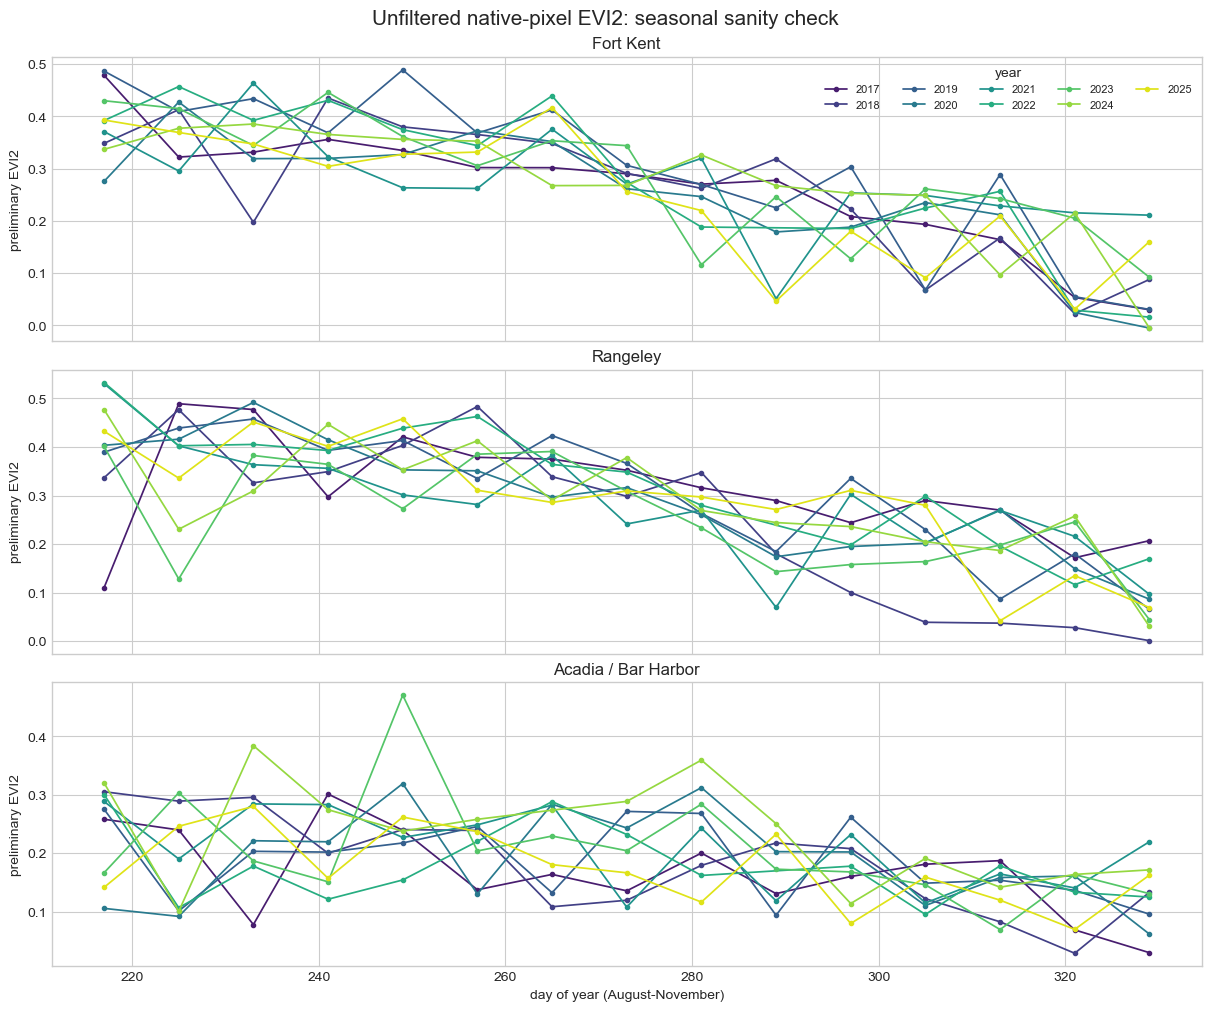

Saved: outputs/eda/provisional_site_evi2_timeseries.png


In [16]:
autumn = site_ts.loc[site_ts["date"].dt.month.isin([8, 9, 10, 11])].copy()
years = sorted(autumn["year"].unique())
colors = plt.cm.viridis(np.linspace(0.08, 0.95, len(years)))

fig, axes = plt.subplots(len(SITES), 1, figsize=(12, 10), sharex=True, constrained_layout=True)
for ax, (site_id, site) in zip(axes, SITES.items()):
    panel = autumn.loc[autumn["site_id"] == site_id]
    for year, color in zip(years, colors):
        line = panel.loc[panel["year"] == year]
        ax.plot(line["doy"], line["evi2_preliminary"], marker="o", ms=3, lw=1.25, color=color, label=str(year))
    ax.set(title=site["name"], ylabel="preliminary EVI2")

axes[-1].set(xlabel="day of year (August-November)")
axes[0].legend(title="year", ncol=5, fontsize=8, loc="best")
fig.suptitle("Unfiltered native-pixel EVI2: seasonal sanity check", fontsize=15)
figure_path = OUT_DIR / "provisional_site_evi2_timeseries.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved: {figure_path}")

## Interpret before moving on

Expected broad pattern: EVI2 is relatively high in late summer and declines through autumn. Do **not** treat spikes, water pixels, cloud-contaminated observations, or these native-point series as final foliage measurements.

After reviewing the outputs, the next notebook should: (1) decode and apply the MODIS QA flags; (2) apply an exact Maine and deciduous/mixed-forest mask; (3) aggregate valid 500 m EVI2 to a fixed 1 km grid; and only then (4) smooth each autumn curve and calculate normalized brownness.